# 02 - Daily patterns in room occupancy

**Question this notebook answers:** how does headcount behave over a day, a week and a few hours, and what does that imply for forecasting 15, 30 or 60 minutes ahead?

Everything uses the cleaned 5-minute data from notebook 01 (`clean_occupancy`). "Usable" bins include the interpolated and assumed-empty ones; "observed" bins are only those with real readings. The difference between the two matters, as the second figure shows.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# find the repository root (works whether Jupyter is started in the root or in notebooks/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "occupancy_forecast").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

RAW = ROOT / "data" / "raw"
OCC = RAW / "5occupancySensor_MayToDec2024_9MRows.csv"
ENV = RAW / "5EnvSensor_MayToDec2024_180kRows.csv"
LOOKUP = RAW / "Sensor_ID_and_Locations.xlsx"
CACHE = ROOT / "data" / "processed" / "binned_5min.parquet"
RESULTS = ROOT / "results"

In [2]:
# 5-minute averages of the 9.1M raw readings (computed once, then cached in data/processed/)
if CACHE.exists():
    binned = pd.read_parquet(CACHE)
else:
    from occupancy_forecast.data_loading import resample_occupancy
    binned = resample_occupancy(OCC, 5)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    binned.to_parquet(CACHE)

def room_names(ids):
    """Readable room names from the location lookup where it has them, else the first 8 characters of the ID."""
    names = {i: i[:8] for i in ids}
    if LOOKUP.exists():
        occ = pd.read_excel(LOOKUP, sheet_name=1)
        for sid, room in zip(occ["SpaceId"], occ["Floor/Room"]):
            if sid in names:
                names[sid] = str(room)
    return names

NAMES = room_names(sorted(binned["floorspaceid"].unique()))
ROOMS = list(NAMES)
COLORS = dict(zip(ROOMS, plt.cm.tab10.colors))
COLOR_OF = {NAMES[r]: COLORS[r] for r in ROOMS}      # colour by room *name*, so a room looks the same in every figure

In [3]:
from occupancy_forecast.cleaning import clean_occupancy

clean = clean_occupancy(binned)
usable = clean[clean["fill_status"] != "missing"].copy()
usable["room"] = usable["floorspaceid"].map(NAMES)
usable["hour"] = usable["timestamp"].dt.hour
usable["weekend"] = usable["timestamp"].dt.dayofweek >= 5
observed = usable[usable["fill_status"] == "observed"]
print(f"{len(usable):,} usable 5-minute bins across {usable['room'].nunique()} rooms")

926,869 usable 5-minute bins across 5 rooms


## 1. Why timestamps must be converted to Melbourne time

The sensor timestamps carry a UTC offset (+10 or +11). If hours are taken from the raw UTC values, the daily pattern is shifted by 10-11 hours and looks backwards: busy at night, quiet in the day. An early exploratory query made exactly this mistake, which is why the loader converts to local time before averaging and a test guards it.

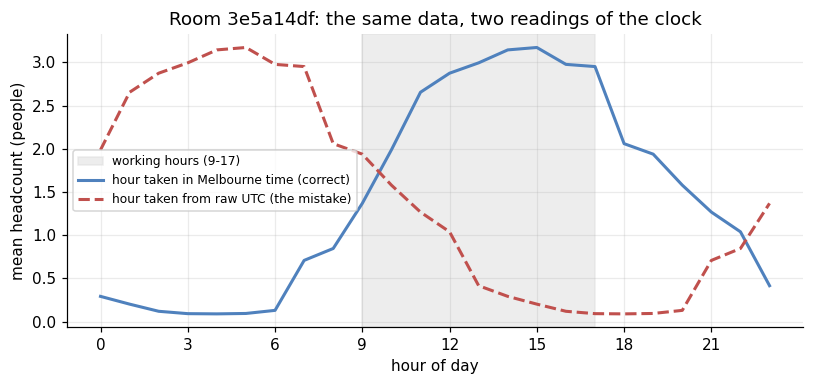

In [4]:
busiest = usable.groupby("room")["headcount"].mean().idxmax()
sub = usable[usable["room"] == busiest]
local = sub.groupby("hour")["headcount"].mean()
utc_like = sub.assign(h=(sub["timestamp"] - pd.Timedelta(hours=10)).dt.hour).groupby("h")["headcount"].mean()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axvspan(9, 17, color="#dddddd", alpha=0.5, label="working hours (9-17)")
ax.plot(local.index, local.values, color="#4f81bd", lw=2, label="hour taken in Melbourne time (correct)")
ax.plot(utc_like.index, utc_like.values, color="#c0504d", lw=2, ls="--", label="hour taken from raw UTC (the mistake)")
ax.set_xlabel("hour of day"); ax.set_ylabel("mean headcount (people)"); ax.set_title(f"Room {busiest}: the same data, two readings of the clock")
ax.set_xticks(range(0, 24, 3)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. The daily profile of each room

Solid lines use every usable bin (including the quiet periods filled in as empty); dashed lines use only bins where the sensor actually reported.

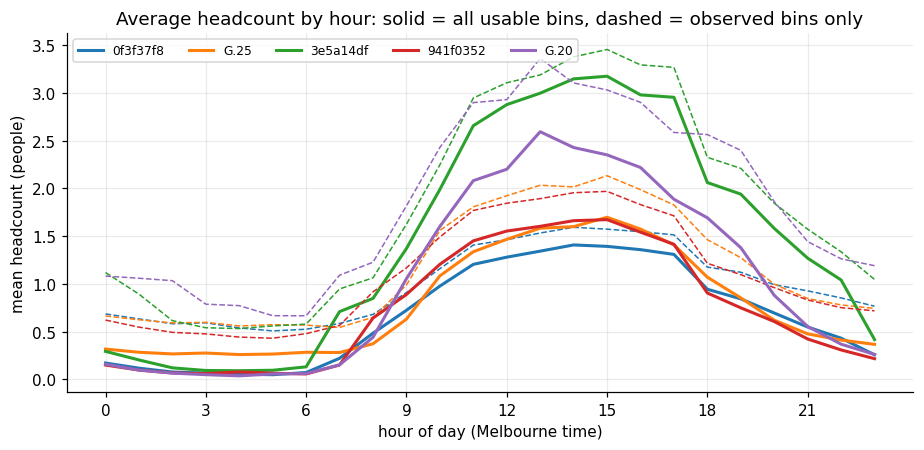

,usable,observed only
"mean headcount, midnight to 6 am",0.13,0.62


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for rid in ROOMS:
    u = usable[usable["floorspaceid"] == rid].groupby("hour")["headcount"].mean()
    o = observed[observed["floorspaceid"] == rid].groupby(observed["timestamp"].dt.hour)["headcount"].mean()
    ax.plot(u.index, u.values, color=COLORS[rid], lw=2, label=NAMES[rid])
    ax.plot(o.index, o.values, color=COLORS[rid], lw=1, ls="--")
ax.set_xlabel("hour of day (Melbourne time)"); ax.set_ylabel("mean headcount (people)")
ax.set_xticks(range(0, 24, 3)); ax.set_title("Average headcount by hour: solid = all usable bins, dashed = observed bins only")
ax.legend(fontsize=8, ncol=5, loc="upper left")
plt.tight_layout(); plt.show()
night = pd.DataFrame({"usable": usable[usable["hour"] < 6]["headcount"].mean(),
                      "observed only": observed[observed["timestamp"].dt.hour < 6]["headcount"].mean()}, index=["mean headcount, midnight to 6 am"])
display(night.round(2))

**Reading this:** every room follows a working-day shape, quiet overnight and busier from about 9 am. The dashed lines sit higher overnight because the sensor mostly reports when something is happening, so the observed bins over-represent activity. That is why the forecast results are reported on measured targets and why the cleaning treats quiet gaps explicitly.

## 3. Weekdays against weekends

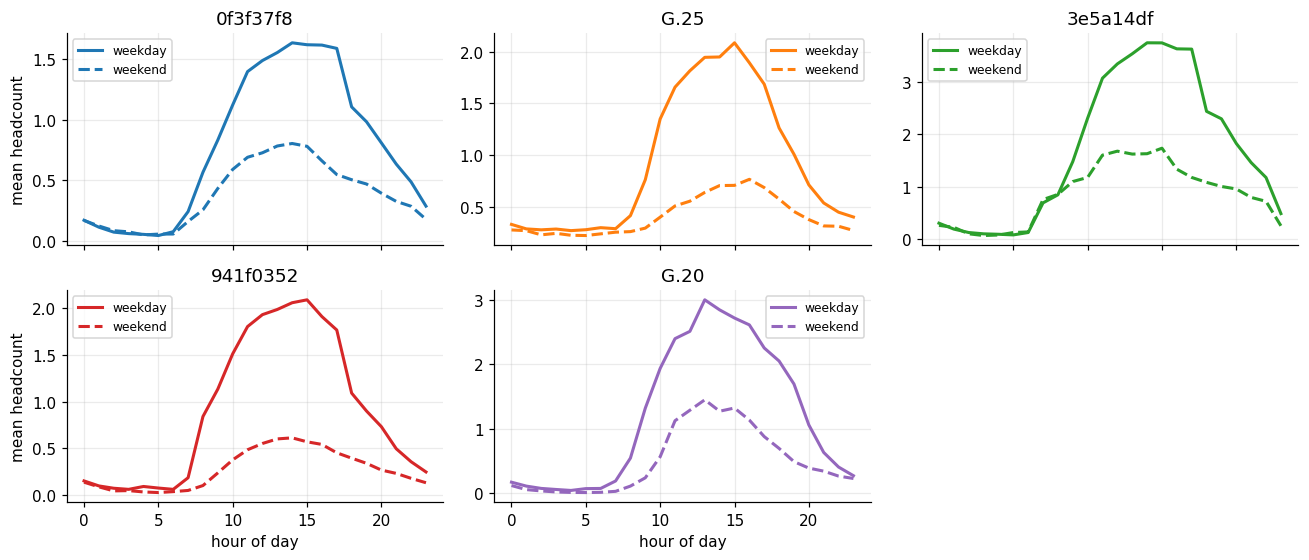

,weekday mean,weekend mean,weekend / weekday
room,,,
0f3f37f8,0.80,0.39,0.49
3e5a14df,1.80,0.88,0.49
941f0352,0.93,0.28,0.30
G.20,1.32,0.55,0.41
G.25,0.94,0.41,0.44


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.2), sharex=True)
for ax, rid in zip(axes.flat, ROOMS):
    d = usable[usable["floorspaceid"] == rid]
    for weekend, style, label in ((False, "-", "weekday"), (True, "--", "weekend")):
        p = d[d["weekend"] == weekend].groupby("hour")["headcount"].mean()
        ax.plot(p.index, p.values, style, color=COLORS[rid], lw=2, label=label)
    ax.set_title(NAMES[rid]); ax.legend(fontsize=8)
for ax in axes[1]: ax.set_xlabel("hour of day")
for ax in axes[:, 0]: ax.set_ylabel("mean headcount")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()
wk = usable.groupby(["room", "weekend"])["headcount"].mean().unstack()
wk.columns = ["weekday mean", "weekend mean"]; wk["weekend / weekday"] = (wk["weekend mean"] / wk["weekday mean"]).round(2)
display(wk.round(2))

## 4. Does the weekly pattern repeat? How much does time of week explain?

A "seasonal average" predicts the headcount from the room, day of week and time of day alone, learned from the first 60% of each room's history and scored on the rest. If weeks repeated closely, this would explain most of the variation (R squared near 1; 0 means no better than the later period's own average; below 0 is worse).

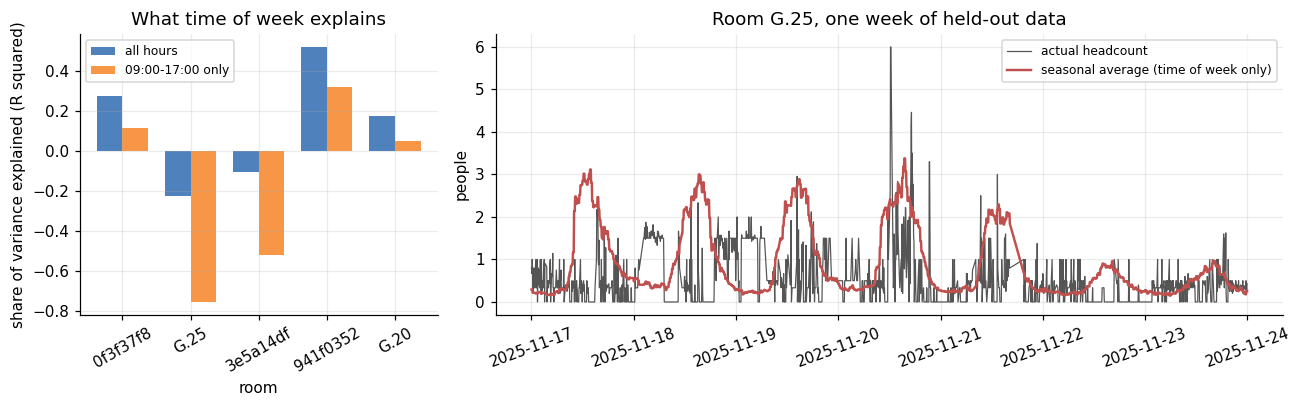

,all hours,09:00-17:00 only
room,,
0f3f37f8,0.28,0.11
G.25,-0.23,-0.75
3e5a14df,-0.11,-0.52
941f0352,0.52,0.32
G.20,0.17,0.05


In [7]:
def slot(d):                                         # day of week x 15-minute slot of day
    return d["timestamp"].dt.dayofweek * 96 + (d["timestamp"].dt.hour * 60 + d["timestamp"].dt.minute) // 15

rows, example = [], {}
for rid in ROOMS:
    g = usable[usable["floorspaceid"] == rid].sort_values("timestamp")
    cut = g["timestamp"].iloc[int(len(g) * 0.6)]
    train, test = g[g["timestamp"] < cut], g[g["timestamp"] >= cut]
    means = train.groupby(slot(train))["headcount"].mean()
    pred = slot(test).map(means).fillna(train["headcount"].mean())
    y, p, hr = test["headcount"].to_numpy(), pred.to_numpy(), test["timestamp"].dt.hour.to_numpy()
    def r2(mask):                                    # 1 = perfect, 0 = no better than the test period's own mean
        return 1 - ((y[mask] - p[mask]) ** 2).sum() / ((y[mask] - y[mask].mean()) ** 2).sum()
    rows.append({"room": NAMES[rid], "all hours": r2(np.ones(len(y), bool)), "09:00-17:00 only": r2((hr >= 9) & (hr < 17))})
    example[rid] = test.assign(seasonal=pred)
r2tab = pd.DataFrame(rows).set_index("room")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
r2tab.plot.bar(ax=axes[0], color=["#4f81bd", "#f79646"], width=0.75)
axes[0].set_ylabel("share of variance explained (R squared)"); axes[0].set_title("What time of week explains")
axes[0].tick_params(axis="x", rotation=30); axes[0].legend(fontsize=8)

rid = ROOMS[1]                                                # one room, one typical week from its later history
ex = example[rid]; start = ex["timestamp"].iloc[len(ex) // 2].normalize()
start = start - pd.Timedelta(days=start.dayofweek)
wk = ex[(ex["timestamp"] >= start) & (ex["timestamp"] < start + pd.Timedelta(days=7))]
axes[1].plot(wk["timestamp"], wk["headcount"], color="#555555", lw=0.8, label="actual headcount")
axes[1].plot(wk["timestamp"], wk["seasonal"], color="#c0504d", lw=1.6, label="seasonal average (time of week only)")
axes[1].set_title(f"Room {NAMES[rid]}, one week of held-out data"); axes[1].set_ylabel("people"); axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
display(r2tab.round(2))

In [8]:
allh, dayh = r2tab["all hours"], r2tab["09:00-17:00 only"]
neg = [room for room in r2tab.index if allh[room] < 0]
display(Markdown(
    f"**Reading this:** time of week explains **little**. Over all hours R squared ranges from **{allh.min():.2f}** to **{allh.max():.2f}**, "
    f"and within working hours from **{dayh.min():.2f}** to **{dayh.max():.2f}**. "
    + (f"A negative value ({', '.join(neg)}) means the weekly pattern learned from the earlier 60% predicts the later 40% *worse* than that later period's "
       f"own average: occupancy has drifted (section 6), so last year's pattern over-predicts. " if neg else "")
    + "Within the working day the actual headcount swings far away from the average pattern: meetings, classes and one-off events cannot be "
      "predicted from the calendar alone. This is why the baselines built on the weekly pattern ('same time last week', 'seasonal average') "
      "score badly in the results, and why recent history is the most useful input."))

**Reading this:** time of week explains **little**. Over all hours R squared ranges from **-0.23** to **0.52**, and within working hours from **-0.75** to **0.32**. A negative value (G.25, 3e5a14df) means the weekly pattern learned from the earlier 60% predicts the later 40% *worse* than that later period's own average: occupancy has drifted (section 6), so last year's pattern over-predicts. Within the working day the actual headcount swings far away from the average pattern: meetings, classes and one-off events cannot be predicted from the calendar alone. This is why the baselines built on the weekly pattern ('same time last week', 'seasonal average') score badly in the results, and why recent history is the most useful input.

## 5. How fast does headcount change? (why a longer horizon is harder)

The average absolute change in headcount over a gap of 5 to 120 minutes is the error a "nothing changes" forecast (persistence) would make at that horizon.

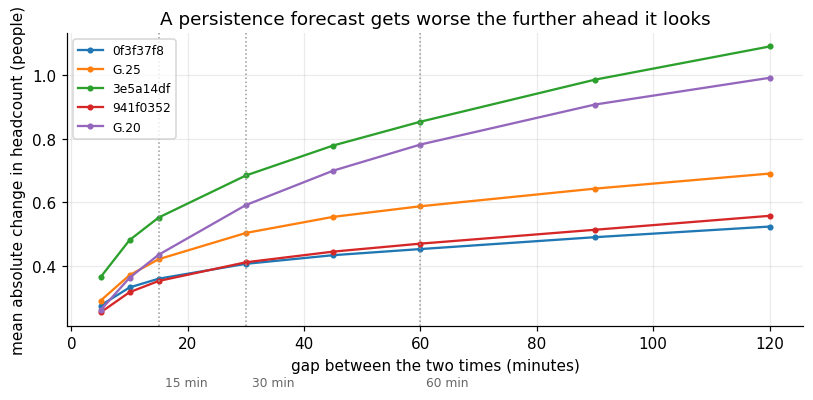

In [9]:
bins = [1, 2, 3, 6, 9, 12, 18, 24]                            # 5 ... 120 minutes
c = clean.sort_values(["floorspaceid", "timestamp"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for rid in ROOMS:
    g = c.loc[c["floorspaceid"] == rid, "headcount"]
    change = [(g - g.shift(k)).abs().mean() for k in bins]
    ax.plot([5 * k for k in bins], change, marker="o", ms=3, color=COLORS[rid], label=NAMES[rid])
for m in (15, 30, 60):
    ax.axvline(m, color="#999999", ls=":", lw=1); ax.text(m + 1, ax.get_ylim()[1] * 0.02, f"{m} min", fontsize=8, color="#666666")
ax.set_xlabel("gap between the two times (minutes)"); ax.set_ylabel("mean absolute change in headcount (people)")
ax.set_title("A persistence forecast gets worse the further ahead it looks"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading this:** the typical change grows steadily with the gap, so any forecast of the next hour is inherently less certain than of the next quarter-hour, and the busiest rooms change fastest. That is also why a model has more room to improve on persistence at longer horizons.

## 6. Has occupancy changed over time?

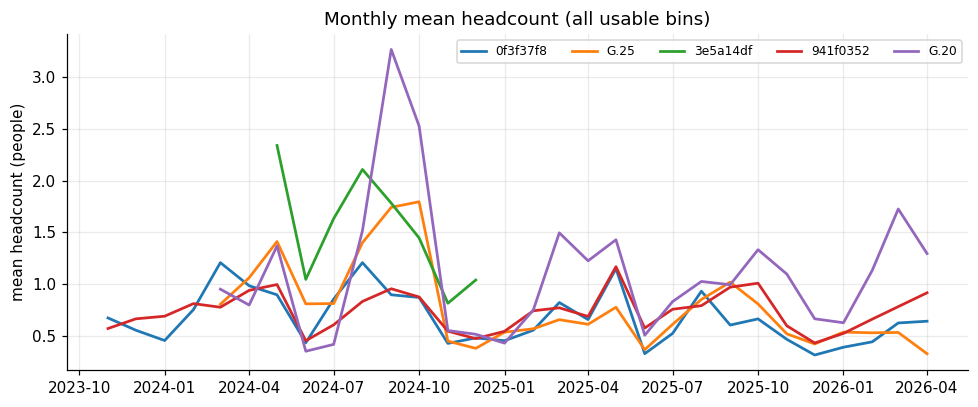

Mean headcount in the earliest third of the data: **1.06**; in the latest third: **0.74** people.

In [10]:
monthly = (usable.groupby(["room", usable["timestamp"].dt.to_period("M")])["headcount"].mean().unstack(0))
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(9, 3.8))
for rid in ROOMS:
    ax.plot(monthly.index, monthly[NAMES[rid]], color=COLORS[rid], lw=1.8, label=NAMES[rid])
ax.set_ylabel("mean headcount (people)"); ax.set_title("Monthly mean headcount (all usable bins)"); ax.legend(fontsize=8, ncol=5)
plt.tight_layout(); plt.show()
first, last = usable[usable["timestamp"] < usable["timestamp"].quantile(0.33)], usable[usable["timestamp"] >= usable["timestamp"].quantile(0.67)]
display(Markdown(f"Mean headcount in the earliest third of the data: **{first['headcount'].mean():.2f}**; in the latest third: **{last['headcount'].mean():.2f}** people."))

**Reading this:** headcount drifts over the period, with clear dips around the Christmas closures and some rooms falling over time. A model trained on earlier months is therefore tested on later months that look a little different. This is why the validation and test errors differ and is listed as a limitation of any score from a time-based split.

## 7. What these patterns imply for the forecasting task

- **Use recent history.** Calendar patterns explain a moderate share of headcount; the latest readings carry far more information about the next half hour.
- **Expect error to grow with horizon**, and report 15, 30 and 60 minutes separately.
- **Report scores on measured targets**, because the quiet periods are easy to predict and inflate the average.
- **Treat any score as specific to this building and period**: five rooms, drifting occupancy, one hub.